## 0. Setup

In [1]:
import os, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances, silhouette_samples, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore')
SEED = 67
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

ROOT = Path(os.environ.get('EUROSAT_ROOT', r'C:\Users\VI-Alumno\Desktop\CNN_EuroSAT\EuroSAT_RGB\EuroSAT_RGB'))
rows = [{'filepath': str(p), 'label': d.name}
        for d in sorted(ROOT.iterdir()) if d.is_dir()
        for p in sorted(d.glob('*.jpg'))]
df = pd.DataFrame(rows)
print('imágenes encontradas:', len(df))

imágenes encontradas: 27000


## 1. Calidad del dataset: lectura única (verifica + carga a memoria + hashes)

In [2]:
N0 = len(df)
X = np.zeros((N0, 64, 64, 3), dtype=np.uint8)   # ~330 MB para 27.000 imágenes
meta = []
for i, fp in enumerate(df['filepath']):
    m = dict(size_bytes=0, corrupt=False, mode=None, w=None, h=None, md5_file=None, md5_pix=None, error='')
    try:
        m['size_bytes'] = os.path.getsize(fp)
        if m['size_bytes'] == 0:
            raise ValueError('archivo vacío')
        with open(fp, 'rb') as f:
            m['md5_file'] = hashlib.md5(f.read()).hexdigest()
        with Image.open(fp) as im:
            im.verify()                          # detecta cabeceras/archivos truncados
        with Image.open(fp) as im:               # verify() invalida el objeto: reabrir
            m['mode'], (m['w'], m['h']) = im.mode, im.size
            rgb = np.asarray(im.convert('RGB'))  # fuerza decodificación completa
        m['md5_pix'] = hashlib.md5(rgb.tobytes()).hexdigest()
        if rgb.shape == (64, 64, 3):
            X[i] = rgb
    except Exception as e:
        m['corrupt'], m['error'] = True, str(e)
    meta.append(m)
    if (i + 1) % 5000 == 0:
        print(f'  {i + 1}/{N0}')
df = pd.concat([df, pd.DataFrame(meta)], axis=1)

df['is_empty'] = df.size_bytes.eq(0)
df['bad_mode'] = (~df.corrupt) & (df['mode'] != 'RGB')
df['bad_size'] = (~df.corrupt) & ((df.w != 64) | (df.h != 64))
df['dup_file'] = df.duplicated('md5_file', keep=False) & df.md5_file.notna()
df['dup_pix'] = df.duplicated('md5_pix', keep=False) & df.md5_pix.notna()

lab_per_hash = df[df.dup_pix].groupby('md5_pix')['label'].nunique()
conflict_hashes = lab_per_hash[lab_per_hash > 1].index   # misma imagen, etiquetas distintas

report = pd.Series({
    'corruptas': int(df.corrupt.sum()),
    'archivos vacíos': int(df.is_empty.sum()),
    'modo != RGB (se convierte)': int(df.bad_mode.sum()),
    'tamaño != 64x64': int(df.bad_size.sum()),
    'duplicados exactos (bytes)': int(df.dup_file.sum()),
    'duplicados exactos (píxeles)': int(df.dup_pix.sum()),
    'grupos duplicados con etiquetas en conflicto': int(len(conflict_hashes)),
})
print(report.to_string())
print('\nmodos:', df['mode'].value_counts(dropna=False).to_dict())
print('tamaños:', df[['w', 'h']].value_counts(dropna=False).to_dict())
if df.dup_pix.any():
    print('\nduplicados por clase:\n', df[df.dup_pix].groupby('label').size().to_string())

# Limpieza: se descartan corruptas/vacías/tamaño incorrecto, grupos con etiqueta en conflicto
# y duplicados exactos (se conserva la primera copia).
drop = (df.corrupt | df.is_empty | df.bad_size
        | df.md5_pix.isin(conflict_hashes)
        | (df.duplicated('md5_pix', keep='first') & df.md5_pix.notna()))
print(f'\neliminadas: {int(drop.sum())} | restantes: {int((~drop).sum())}')
keep = ~drop.values
df = df[keep].reset_index(drop=True)
X = X[keep]
y = df['label'].values
classes = sorted(df['label'].unique())
K = len(classes)

  5000/27000
  10000/27000
  15000/27000
  20000/27000
  25000/27000
corruptas                                       0
archivos vacíos                                 0
modo != RGB (se convierte)                      0
tamaño != 64x64                                 0
duplicados exactos (bytes)                      0
duplicados exactos (píxeles)                    0
grupos duplicados con etiquetas en conflicto    0

modos: {'RGB': 27000}
tamaños: {(64, 64): 27000}

eliminadas: 0 | restantes: 27000


## 2. Balance de clases

                         n  rel_freq     pct  dev_pp  dev_rel_%  class_weight
label                                                                        
AnnualCrop            3000     0.111  11.111   1.111     11.111          0.90
Forest                3000     0.111  11.111   1.111     11.111          0.90
HerbaceousVegetation  3000     0.111  11.111   1.111     11.111          0.90
Residential           3000     0.111  11.111   1.111     11.111          0.90
SeaLake               3000     0.111  11.111   1.111     11.111          0.90
Highway               2500     0.093   9.259  -0.741     -7.407          1.08
PermanentCrop         2500     0.093   9.259  -0.741     -7.407          1.08
Industrial            2500     0.093   9.259  -0.741     -7.407          1.08
River                 2500     0.093   9.259  -0.741     -7.407          1.08
Pasture               2000     0.074   7.407  -2.593    -25.926          1.35

ratio max/min: 1.50 | std de % por clase: 1.29 pp | entropía no

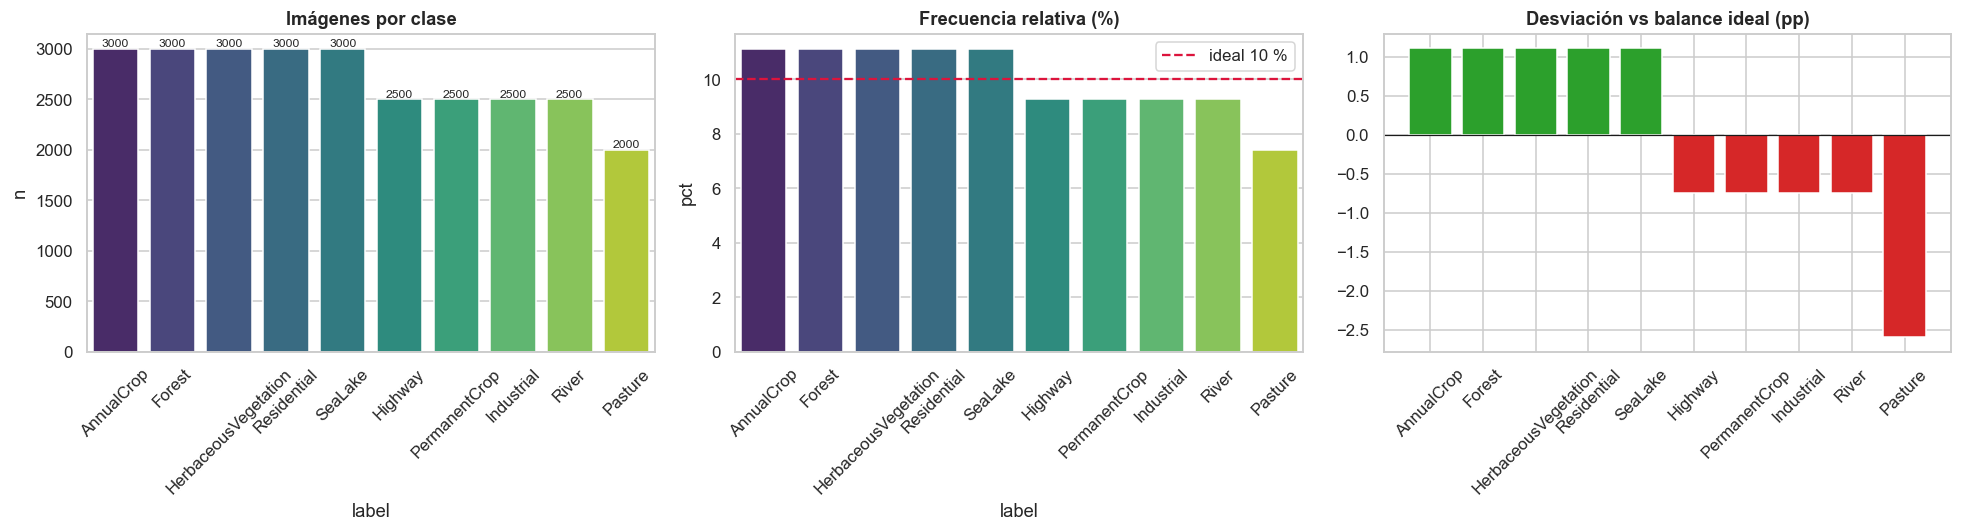

In [3]:
counts = df['label'].value_counts()
bal = pd.DataFrame({'n': counts})
bal['rel_freq'] = bal.n / bal.n.sum()
bal['pct'] = bal.rel_freq * 100
IDEAL = 100 / K
bal['dev_pp'] = bal.pct - IDEAL                      # puntos porcentuales vs 10 %
bal['dev_rel_%'] = (bal.pct / IDEAL - 1) * 100       # desviación relativa
bal['class_weight'] = bal.n.sum() / (K * bal.n)      # estilo sklearn 'balanced'
print(bal.round(3).to_string())
print(f"\nratio max/min: {bal.n.max() / bal.n.min():.2f} | "
      f"std de % por clase: {bal.pct.std():.2f} pp | "
      f"entropía normalizada: {-(bal.rel_freq * np.log(bal.rel_freq)).sum() / np.log(K):.4f}")

b = bal.reset_index().rename(columns={'index': 'label'})
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=b, x='label', y='n', hue='label', palette='viridis', legend=False, ax=ax[0])
ax[0].set_title('Imágenes por clase'); ax[0].tick_params(axis='x', rotation=45)
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha='center', va='bottom', fontsize=8)
sns.barplot(data=b, x='label', y='pct', hue='label', palette='viridis', legend=False, ax=ax[1])
ax[1].axhline(IDEAL, color='crimson', ls='--', label=f'ideal {IDEAL:.0f} %')
ax[1].set_title('Frecuencia relativa (%)'); ax[1].legend(); ax[1].tick_params(axis='x', rotation=45)
colors = ['tab:green' if v >= 0 else 'tab:red' for v in b.dev_pp]
ax[2].bar(b.label, b.dev_pp, color=colors)
ax[2].axhline(0, color='k', lw=.8)
ax[2].set_title('Desviación vs balance ideal (pp)'); ax[2].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

## 3. Muestra visual por clase (9 imágenes por clase, 10 filas x 9 columnas)

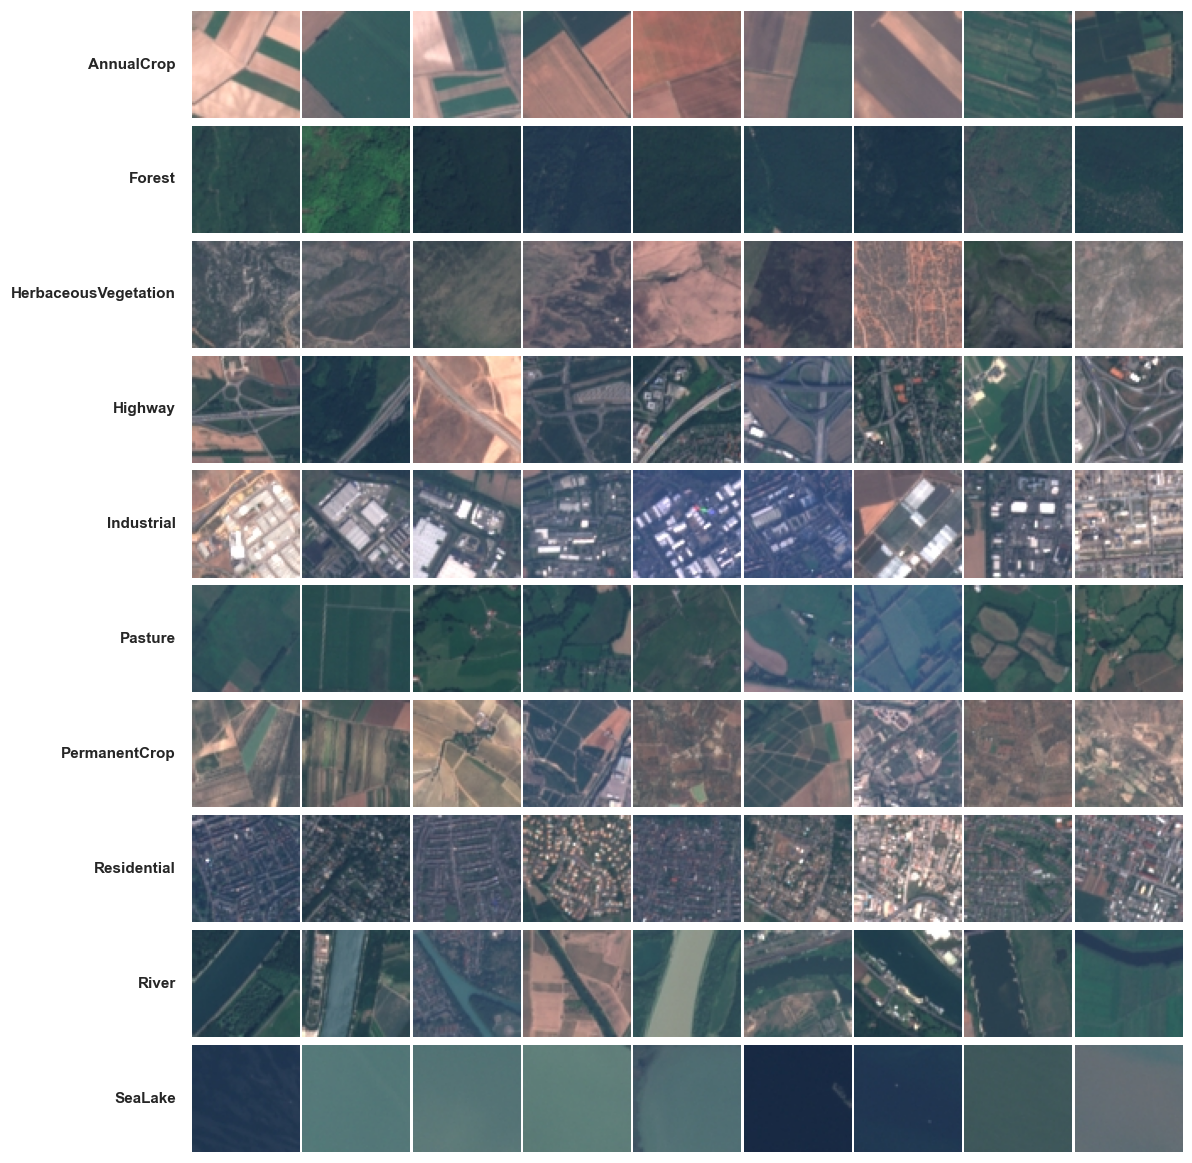

In [4]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(K, 9, figsize=(12, 1.35 * K))
for i, c in enumerate(classes):
    sel = rng.choice(np.where(y == c)[0], 9, replace=False)
    for j, k in enumerate(sel):
        axes[i, j].imshow(X[k]); axes[i, j].axis('off')
    axes[i, 0].text(-0.15, 0.5, c, transform=axes[i, 0].transAxes, ha='right', va='center', fontsize=10, fontweight='bold')
fig.subplots_adjust(left=0.15, wspace=0.03, hspace=0.05)
plt.show()

def zoom_class(c, n=9, seed=SEED):
    """Cuadrícula 3x3 ampliada de una clase (útil para inspeccionar errores)."""
    sel = np.random.default_rng(seed).choice(np.where(y == c)[0], n, replace=False)
    fig, axs = plt.subplots(3, 3, figsize=(5, 5))
    for a, k in zip(axs.ravel(), sel):
        a.imshow(X[k], interpolation='nearest'); a.axis('off')
    fig.suptitle(c); plt.tight_layout(); plt.show()

# zoom_class('Pasture'); zoom_class('Highway')   # descomenta para ver clases puntuales

## 4. Estadísticas RGB: features por imagen (una sola pasada por chunks)

GLOBAL  mean: [0.3444 0.3803 0.4078] | std: [0.2027 0.1369 0.1155]
                      mean_R  mean_G  mean_B   std_R   std_G   std_B
AnnualCrop            0.5082  0.4707  0.4595  0.2353  0.1281  0.1030
Forest                0.1544  0.2528  0.2979  0.0306  0.0360  0.0324
HerbaceousVegetation  0.3849  0.3873  0.4076  0.1568  0.1102  0.0926
Highway               0.3452  0.3791  0.4054  0.1895  0.1225  0.1034
Industrial            0.4839  0.4918  0.5269  0.2195  0.1824  0.1682
Pasture               0.2428  0.3469  0.3693  0.0781  0.0533  0.0781
PermanentCrop         0.4789  0.4550  0.4472  0.1895  0.1265  0.1003
Residential           0.3924  0.4070  0.4432  0.1603  0.1159  0.1025
River                 0.2629  0.3397  0.3800  0.1308  0.0937  0.0801
SeaLake               0.1886  0.2856  0.3493  0.0994  0.1063  0.0703

Normalize(mean=(0.3444, 0.3803, 0.4078), std=(0.2027, 0.1369, 0.1155))


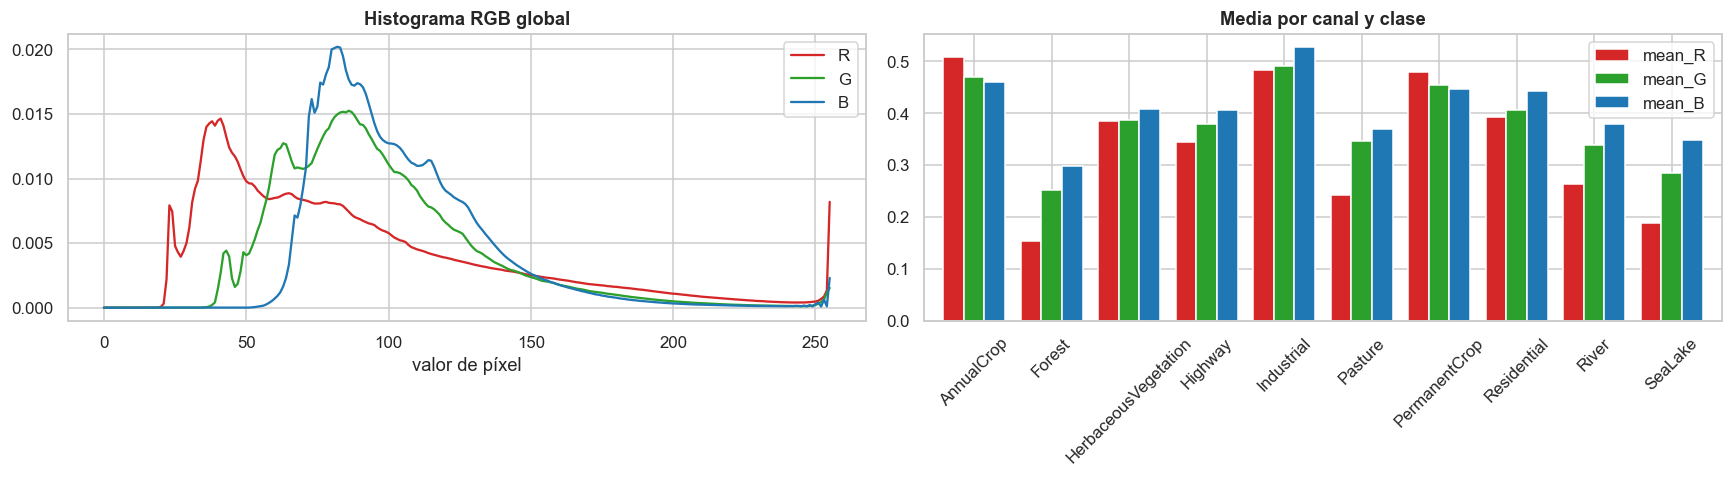

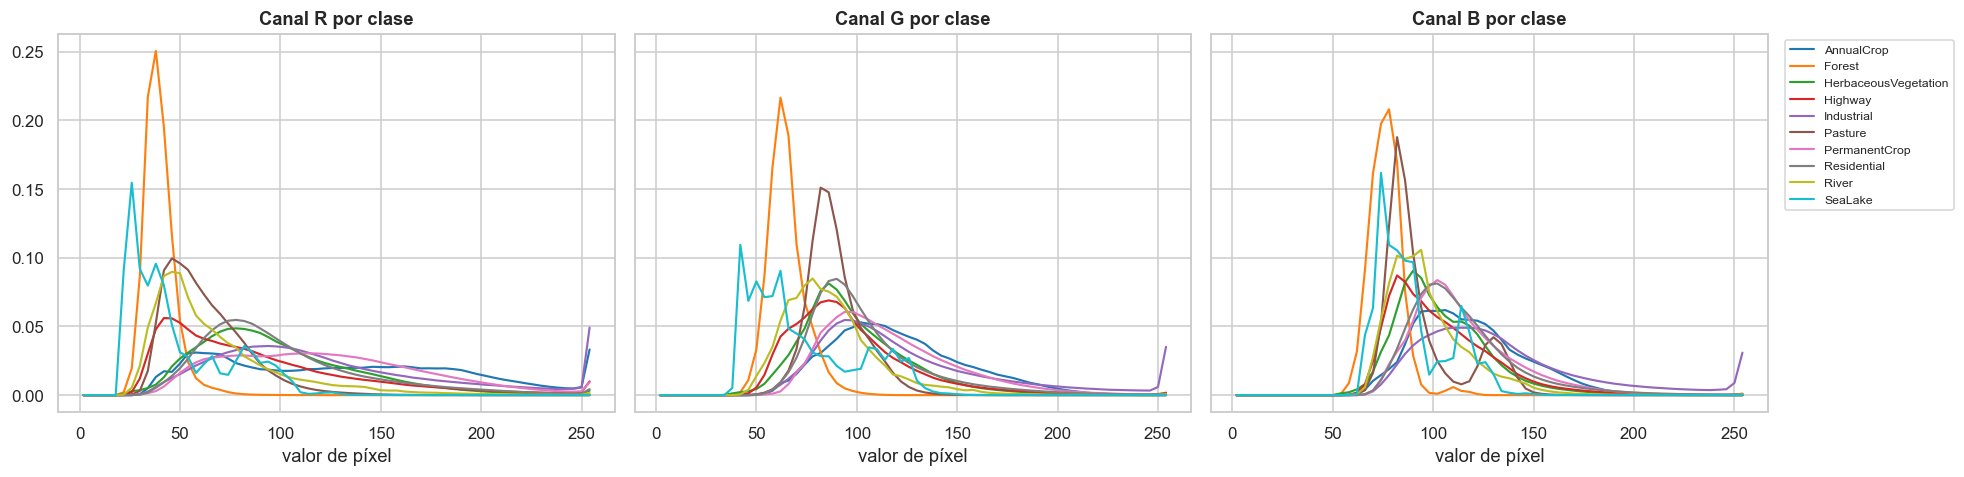

In [5]:
def chunks(n, size=2000):
    for s in range(0, n, size):
        yield slice(s, min(s + size, n))

LUMA = np.array([0.299, 0.587, 0.114], dtype=np.float32)
N = len(X)
mean_rgb = np.zeros((N, 3), np.float32); meansq_rgb = np.zeros((N, 3), np.float32); std_rgb = np.zeros((N, 3), np.float32)
gray_mean = np.zeros(N, np.float32); gray_std = np.zeros(N, np.float32)
hist16 = np.zeros((N, 48), np.float32)    # histograma de 16 bins por canal (R|G|B)

for s in chunks(N):
    xb = X[s]
    c = xb.astype(np.float32) / 255.0
    mean_rgb[s] = c.mean((1, 2)); std_rgb[s] = c.std((1, 2)); meansq_rgb[s] = (c ** 2).mean((1, 2))
    g = c @ LUMA
    gray_mean[s] = g.mean((1, 2)); gray_std[s] = g.std((1, 2))
    bins = (xb >> 4).astype(np.int64)
    for ch in range(3):
        bc = bins[..., ch].reshape(len(xb), -1)
        for k in range(16):
            hist16[s, ch * 16 + k] = (bc == k).mean(1)

def mean_std(mask):
    """Media y desviación estándar a nivel de píxel (escala 0-1) para un subconjunto."""
    mu = mean_rgb[mask].astype(np.float64).mean(0)
    sd = np.sqrt(meansq_rgb[mask].astype(np.float64).mean(0) - mu ** 2)
    return mu, sd

g_mean, g_std = mean_std(np.ones(N, bool))
print('GLOBAL  mean:', np.round(g_mean, 4), '| std:', np.round(g_std, 4))

rgb_cls = pd.DataFrame(
    [np.r_[mean_std(y == c)] for c in classes], index=classes,
    columns=['mean_R', 'mean_G', 'mean_B', 'std_R', 'std_G', 'std_B'])
print(rgb_cls.round(4).to_string())
print(f"\nNormalize(mean={tuple(np.round(g_mean, 4).tolist())}, std={tuple(np.round(g_std, 4).tolist())})")

chan_names, chan_cols = ['R', 'G', 'B'], ['tab:red', 'tab:green', 'tab:blue']

# Fig 1: histograma global + medias por clase
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for ch in range(3):
    h = np.bincount(X[..., ch].ravel(), minlength=256) / X[..., ch].size
    ax[0].plot(h, color=chan_cols[ch], label=chan_names[ch])
ax[0].set_title('Histograma RGB global'); ax[0].set_xlabel('valor de píxel'); ax[0].legend()
rgb_cls[['mean_R', 'mean_G', 'mean_B']].plot(kind='bar', color=chan_cols, ax=ax[1], width=.8)
ax[1].set_title('Media por canal y clase'); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

# Fig 2: histograma por canal, una curva por clase
pal = sns.color_palette('tab10', K)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for k, c in enumerate(classes):
    Xc = X[y == c]
    for ch in range(3):
        h = np.bincount(Xc[..., ch].ravel(), minlength=256) / Xc[..., ch].size
        ax[ch].plot(np.arange(64) * 4 + 2, h.reshape(64, 4).sum(1), color=pal[k], label=c, lw=1.4)
for ch in range(3):
    ax[ch].set_title(f'Canal {chan_names[ch]} por clase'); ax[ch].set_xlabel('valor de píxel')
ax[2].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()

## 5. Estadísticas por clase: brillo, contraste, intensidad

                      brightness  brightness_sd  contrast  contrast_sd  intensity
label                                                                            
Forest                    0.2285         0.0274    0.0150       0.0058     0.2350
SeaLake                   0.2639         0.0966    0.0113       0.0153     0.2745
Pasture                   0.3183         0.0437    0.0377       0.0138     0.3197
River                     0.3213         0.0583    0.0753       0.0335     0.3275
Highway                   0.3720         0.1035    0.0862       0.0319     0.3766
HerbaceousVegetation      0.3889         0.0978    0.0618       0.0340     0.3933
Residential               0.4068         0.0927    0.0812       0.0265     0.4142
PermanentCrop             0.4612         0.1060    0.0867       0.0314     0.4604
AnnualCrop                0.4806         0.1108    0.0994       0.0416     0.4795
Industrial                0.4934         0.0903    0.1634       0.0378     0.5008

Más oscuras : [

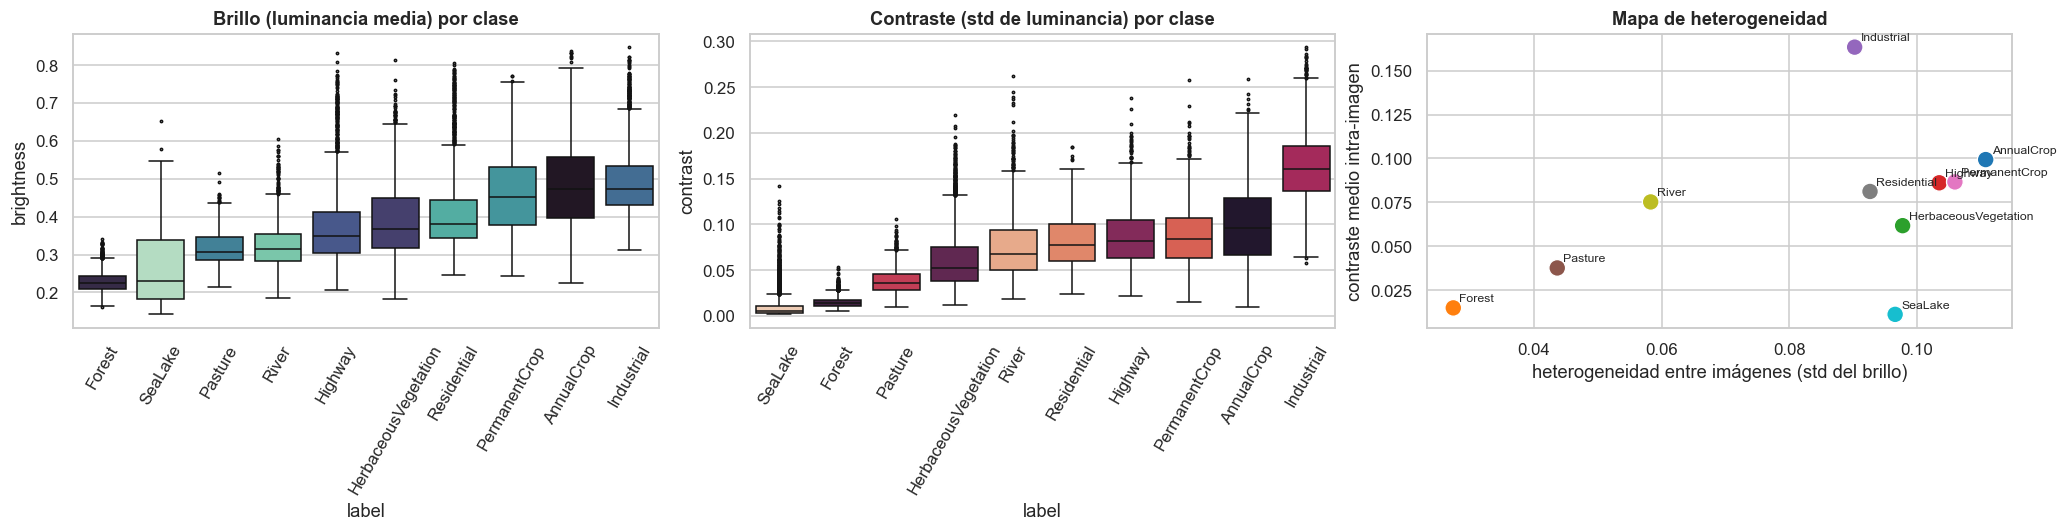

In [6]:
feat = pd.DataFrame({'label': y, 'brightness': gray_mean, 'contrast': gray_std, 'intensity': mean_rgb.mean(1)})
agg = feat.groupby('label').agg(
    brightness=('brightness', 'mean'), brightness_sd=('brightness', 'std'),
    contrast=('contrast', 'mean'), contrast_sd=('contrast', 'std'),
    intensity=('intensity', 'mean'))
print(agg.sort_values('brightness').round(4).to_string())
print('\nMás oscuras :', agg.brightness.nsmallest(3).index.tolist())
print('Más claras  :', agg.brightness.nlargest(3).index.tolist())
print('Más heterogéneas entre imágenes (brightness_sd):', agg.brightness_sd.nlargest(3).index.tolist())
print('Más heterogéneas dentro de la imagen (contrast):', agg.contrast.nlargest(3).index.tolist())
print('Más homogéneas (contrast):', agg.contrast.nsmallest(3).index.tolist())

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
order_b = feat.groupby('label').brightness.median().sort_values().index
sns.boxplot(data=feat, x='label', y='brightness', hue='label', order=order_b, palette='mako', legend=False, fliersize=1.5, ax=ax[0])
ax[0].set_title('Brillo (luminancia media) por clase'); ax[0].tick_params(axis='x', rotation=60)
order_c = feat.groupby('label').contrast.median().sort_values().index
sns.boxplot(data=feat, x='label', y='contrast', hue='label', order=order_c, palette='rocket', legend=False, fliersize=1.5, ax=ax[1])
ax[1].set_title('Contraste (std de luminancia) por clase'); ax[1].tick_params(axis='x', rotation=60)
sns.scatterplot(data=agg.reset_index(), x='brightness_sd', y='contrast', hue='label', s=120, palette='tab10', ax=ax[2])
for c, r in agg.iterrows():
    ax[2].annotate(c, (r.brightness_sd, r.contrast), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax[2].set_xlabel('heterogeneidad entre imágenes (std del brillo)'); ax[2].set_ylabel('contraste medio intra-imagen')
ax[2].set_title('Mapa de heterogeneidad'); ax[2].legend_.remove()
plt.tight_layout(); plt.show()

## 6. Similitud entre clases con features simples de color

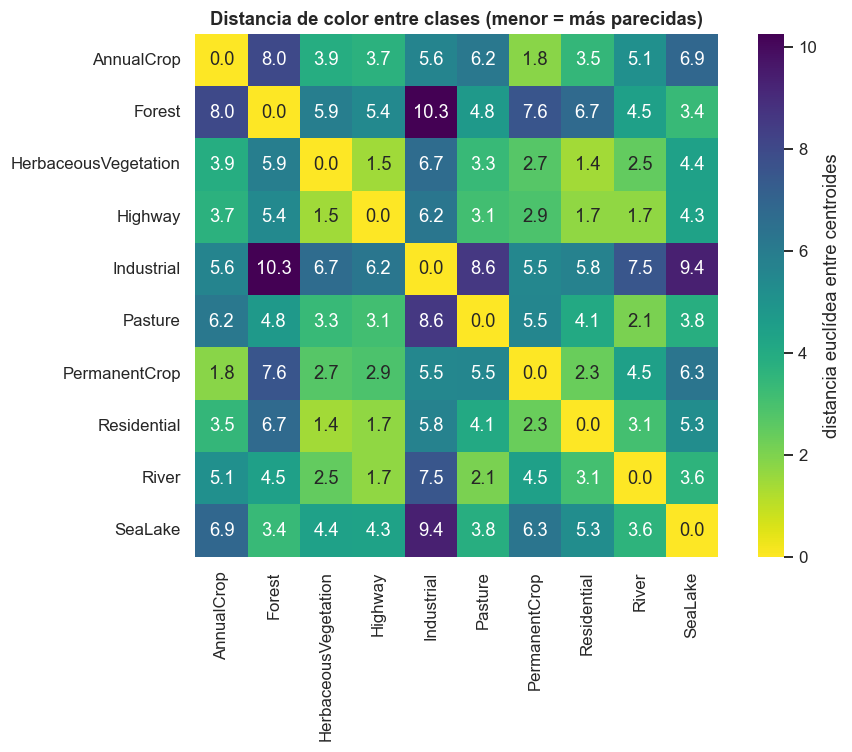

Pares más parecidos:
              clase_a       clase_b  dist
HerbaceousVegetation   Residential  1.42
HerbaceousVegetation       Highway  1.47
             Highway         River  1.69
             Highway   Residential  1.71
          AnnualCrop PermanentCrop  1.81
             Pasture         River  2.06
       PermanentCrop   Residential  2.34
HerbaceousVegetation         River  2.48

Pares más distintos:
    clase_a       clase_b  dist
    Forest PermanentCrop  7.57
AnnualCrop        Forest  8.01
Industrial       Pasture  8.58
Industrial       SeaLake  9.35
    Forest    Industrial 10.26

Vecino más cercano por clase:
 AnnualCrop                     PermanentCrop
Forest                               SeaLake
HerbaceousVegetation             Residential
Highway                 HerbaceousVegetation
Industrial                     PermanentCrop
Pasture                                River
PermanentCrop                     AnnualCrop
Residential             HerbaceousVegetation
River   

In [7]:
# 54 dims: media RGB (3) + std RGB (3) + histogramas de 16 bins por canal (48), estandarizadas.
F = np.hstack([mean_rgb, std_rgb, hist16])
Z = StandardScaler().fit_transform(F)
cent = np.vstack([Z[y == c].mean(0) for c in classes])
D = pairwise_distances(cent)
Ddf = pd.DataFrame(D, index=classes, columns=classes)

plt.figure(figsize=(9, 7))
sns.heatmap(Ddf, annot=True, fmt='.1f', cmap='viridis_r', square=True, cbar_kws={'label': 'distancia euclídea entre centroides'})
plt.title('Distancia de color entre clases (menor = más parecidas)')
plt.tight_layout(); plt.show()

iu = np.triu_indices(K, 1)
pairs = pd.DataFrame({'clase_a': np.array(classes)[iu[0]], 'clase_b': np.array(classes)[iu[1]], 'dist': D[iu]}).sort_values('dist')
print('Pares más parecidos:\n', pairs.head(8).round(2).to_string(index=False))
print('\nPares más distintos:\n', pairs.tail(5).round(2).to_string(index=False))
D_nn = D + np.eye(K) * 1e9
print('\nVecino más cercano por clase:\n', pd.Series([classes[j] for j in D_nn.argmin(1)], index=classes).to_string())

## 7. Complejidad: varianza, dispersión intra/inter-clase, separabilidad, baseline de color

                      var_mean  intra_mean  intra_p90  inter_mean  inter_min               nearest  separability  silhouette
label                                                                                                                       
AnnualCrop               1.409       7.745     12.142       4.970      1.806         PermanentCrop         0.233      -0.223
HerbaceousVegetation     0.621       5.258      8.196       3.593      1.424           Residential         0.271      -0.167
Residential              1.392       4.919      7.090       3.765      1.424  HerbaceousVegetation         0.290      -0.035
PermanentCrop            0.724       5.538      8.507       4.347      1.806            AnnualCrop         0.326      -0.089
Highway                  0.609       4.369      7.186       3.400      1.467  HerbaceousVegetation         0.336      -0.128
River                    0.273       3.488      5.489       3.839      1.694               Highway         0.486       0.013


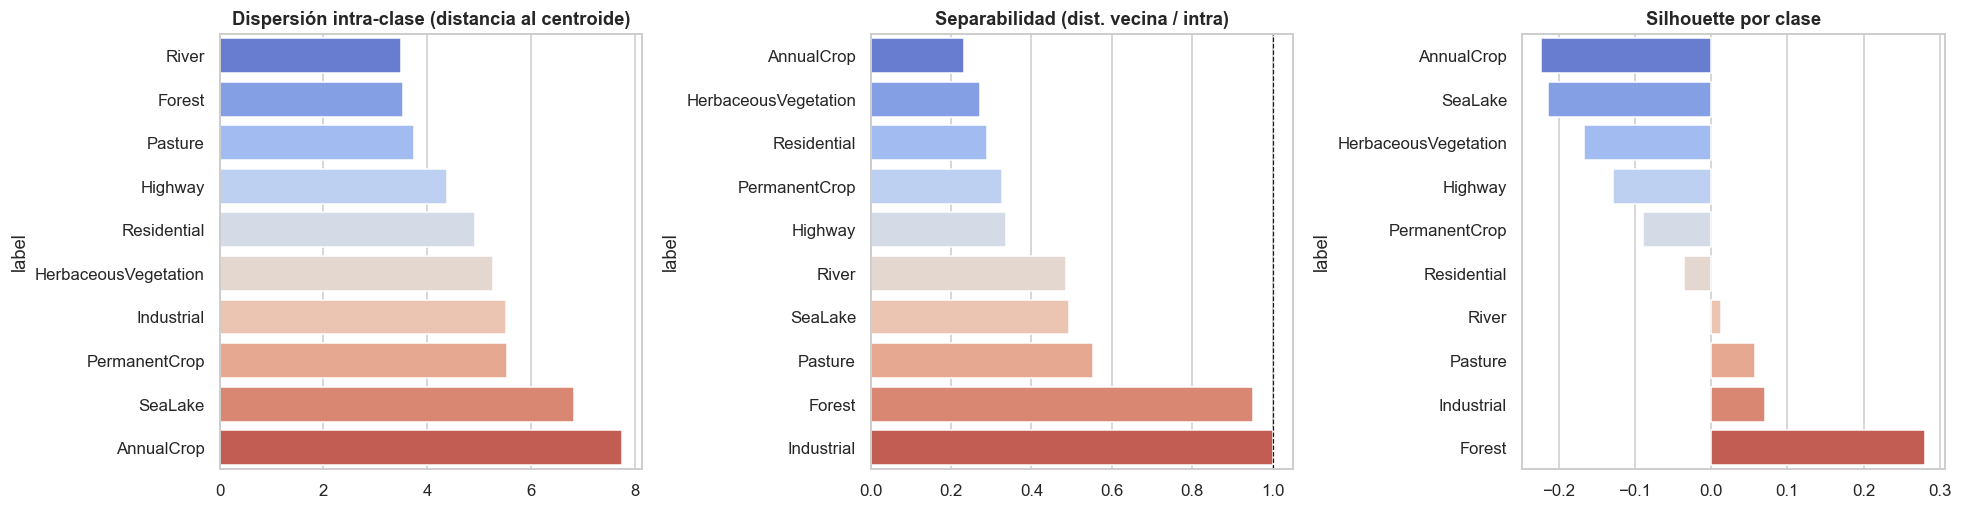


RF solo color -> F1 macro: 0.7969
                      precision    recall  f1-score   support

          AnnualCrop      0.813     0.872     0.842       600
              Forest      0.918     0.957     0.937       600
HerbaceousVegetation      0.792     0.762     0.777       600
             Highway      0.586     0.448     0.508       500
          Industrial      0.854     0.900     0.876       500
             Pasture      0.806     0.863     0.833       400
       PermanentCrop      0.725     0.740     0.733       500
         Residential      0.772     0.873     0.819       600
               River      0.725     0.684     0.704       500
             SeaLake      0.977     0.907     0.940       600

            accuracy                          0.806      5400
           macro avg      0.797     0.800     0.797      5400
        weighted avg      0.802     0.806     0.802      5400



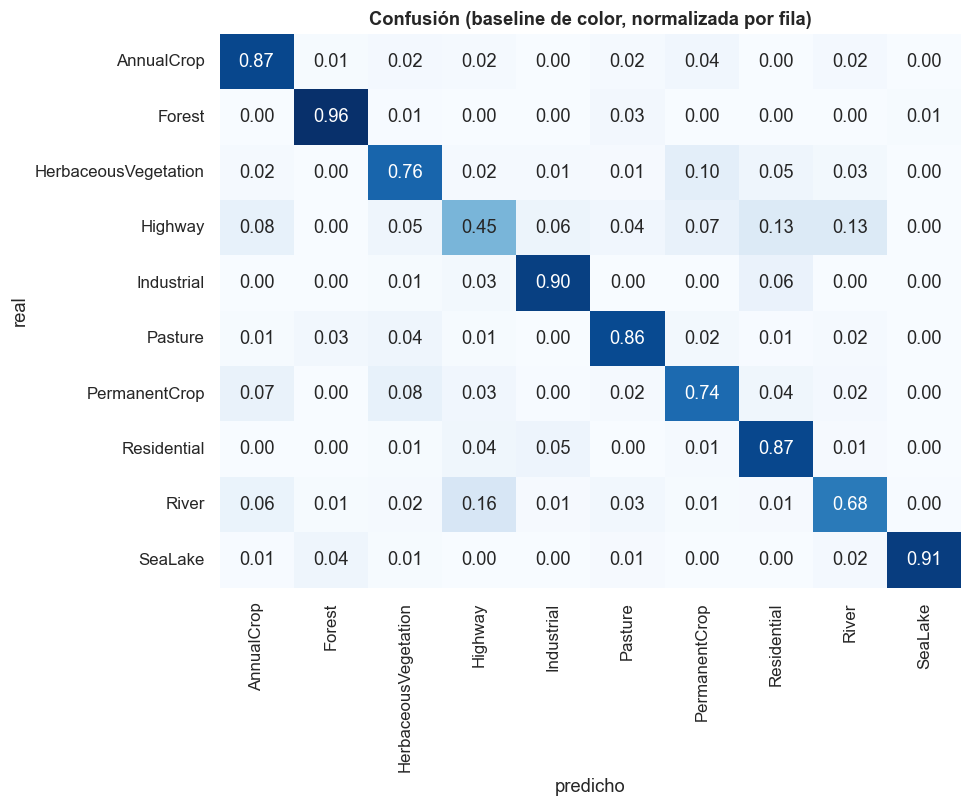

Top confusiones: [('River', 'Highway', 0.16), ('Highway', 'Residential', 0.13), ('Highway', 'River', 0.13), ('HerbaceousVegetation', 'PermanentCrop', 0.1), ('Highway', 'AnnualCrop', 0.08), ('PermanentCrop', 'HerbaceousVegetation', 0.08)]


In [8]:
cx_rows = []
for k, c in enumerate(classes):
    Zc = Z[y == c]
    d_intra = np.linalg.norm(Zc - cent[k], axis=1)
    others = np.delete(D[k], k)
    names_other = [cl for j, cl in enumerate(classes) if j != k]
    cx_rows.append(dict(label=c, var_mean=Zc.var(0).mean(), intra_mean=d_intra.mean(),
                        intra_p90=np.percentile(d_intra, 90), inter_mean=others.mean(),
                        inter_min=others.min(), nearest=names_other[others.argmin()]))
cx = pd.DataFrame(cx_rows).set_index('label')
cx['separability'] = cx.inter_min / cx.intra_mean       # <1 => solapamiento probable con su vecina

n_sub = min(6000, len(Z) // 2)
sub, _ = train_test_split(np.arange(len(Z)), train_size=n_sub, stratify=y, random_state=SEED)
sil = silhouette_samples(Z[sub], y[sub])
cx['silhouette'] = pd.Series(sil).groupby(y[sub]).mean().reindex(classes).values
print(cx.round(3).sort_values('separability').to_string())
print(f'\nSilhouette global (color, {n_sub} muestras): {sil.mean():.3f}  (cerca de 0 => clases solapadas en color)')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a, col, ttl in zip(ax, ['intra_mean', 'separability', 'silhouette'],
                       ['Dispersión intra-clase (distancia al centroide)', 'Separabilidad (dist. vecina / intra)', 'Silhouette por clase']):
    s = cx[col].sort_values()
    sns.barplot(x=s.values, y=s.index, hue=s.index, palette='coolwarm', legend=False, ax=a)
    a.set_title(ttl)
ax[1].axvline(1, color='k', ls='--', lw=.8)
plt.tight_layout(); plt.show()

# Baseline "sin CNN": Random Forest con solo color -> piso de referencia y mapa de confusiones
tr_i, va_i = train_test_split(np.arange(len(F)), test_size=0.2, stratify=y, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, class_weight='balanced', random_state=SEED).fit(F[tr_i], y[tr_i])
pred = rf.predict(F[va_i])
print(f'\nRF solo color -> F1 macro: {f1_score(y[va_i], pred, average="macro"):.4f}')
print(classification_report(y[va_i], pred, digits=3))
cm = confusion_matrix(y[va_i], pred, labels=classes, normalize='true')
plt.figure(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=False)
plt.title('Confusión (baseline de color, normalizada por fila)'); plt.xlabel('predicho'); plt.ylabel('real')
plt.tight_layout(); plt.show()
off = [(classes[i], classes[j], cm[i, j]) for i in range(K) for j in range(K) if i != j]
print('Top confusiones:', [(a, b, round(float(v), 2)) for a, b, v in sorted(off, key=lambda t: -t[2])[:6]])

## 8. Split train/validation

train: 21600 | val: 5400 | fugas por duplicado exacto: 0
                      total_%  train_%   val_%  n_train  n_val  max_diff_pp
AnnualCrop             11.111   11.111  11.111     2400    600          0.0
Forest                 11.111   11.111  11.111     2400    600          0.0
HerbaceousVegetation   11.111   11.111  11.111     2400    600          0.0
Highway                 9.259    9.259   9.259     2000    500          0.0
Industrial              9.259    9.259   9.259     2000    500          0.0
Pasture                 7.407    7.407   7.407     1600    400          0.0
PermanentCrop           9.259    9.259   9.259     2000    500          0.0
Residential            11.111   11.111  11.111     2400    600          0.0
River                   9.259    9.259   9.259     2000    500          0.0
SeaLake                11.111   11.111  11.111     2400    600          0.0


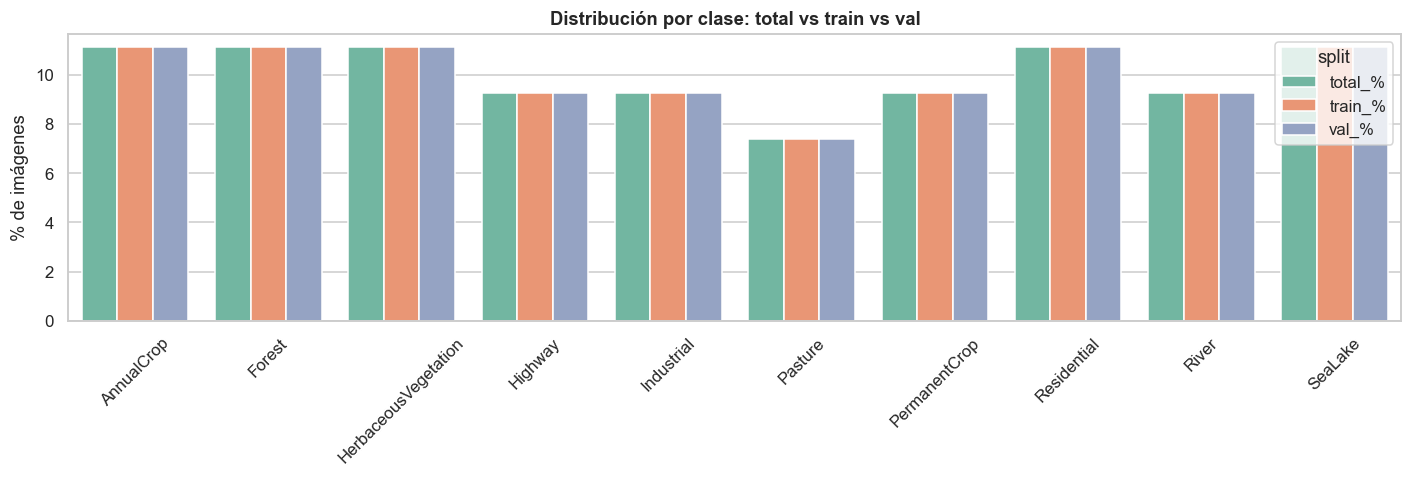


TRAIN mean: (0.3439, 0.38, 0.4076) | std: (0.2024, 0.1367, 0.1154)
                      n_train  w_balanced  w_sqrt
AnnualCrop               2400        0.90   0.949
Forest                   2400        0.90   0.949
HerbaceousVegetation     2400        0.90   0.949
Highway                  2000        1.08   1.039
Industrial               2000        1.08   1.039
Pasture                  1600        1.35   1.162
PermanentCrop            2000        1.08   1.039
Residential              2400        0.90   0.949
River                    2000        1.08   1.039
SeaLake                  2400        0.90   0.949


In [9]:
VAL_SIZE = 0.20
idx_all = np.arange(len(df))
train_idx, val_idx = train_test_split(idx_all, test_size=VAL_SIZE, stratify=y, random_state=SEED, shuffle=True)

# Verificación anti-fuga: ninguna imagen idéntica en ambos splits
leak = set(df.md5_pix.iloc[train_idx]) & set(df.md5_pix.iloc[val_idx])
print(f'train: {len(train_idx)} | val: {len(val_idx)} | fugas por duplicado exacto: {len(leak)}')

dist = pd.DataFrame({
    'total_%': pd.Series(y).value_counts(normalize=True) * 100,
    'train_%': pd.Series(y[train_idx]).value_counts(normalize=True) * 100,
    'val_%': pd.Series(y[val_idx]).value_counts(normalize=True) * 100}).loc[classes]
dist['n_train'] = pd.Series(y[train_idx]).value_counts().reindex(classes)
dist['n_val'] = pd.Series(y[val_idx]).value_counts().reindex(classes)
dist['max_diff_pp'] = (dist[['train_%', 'val_%']].sub(dist['total_%'], axis=0)).abs().max(axis=1)
print(dist.round(3).to_string())

melt = dist[['total_%', 'train_%', 'val_%']].reset_index().melt(id_vars='index', var_name='split', value_name='pct')
plt.figure(figsize=(13, 4.5))
sns.barplot(data=melt, x='index', y='pct', hue='split', palette='Set2')
plt.xticks(rotation=45); plt.xlabel(''); plt.ylabel('% de imágenes'); plt.title('Distribución por clase: total vs train vs val')
plt.tight_layout(); plt.show()

# Estadísticas de normalización SOLO con train (evita fuga de información)
tr_mean, tr_std = mean_std(np.isin(idx_all, train_idx))
print('\nTRAIN mean:', tuple(np.round(tr_mean, 4).tolist()), '| std:', tuple(np.round(tr_std, 4).tolist()))

# Pesos de clase (calculados en train): completos y suavizados (raíz)
cls2i = {c: i for i, c in enumerate(classes)}
y_int = np.array([cls2i[c] for c in y])
cnt_tr = np.bincount(y_int[train_idx], minlength=K)
class_w = len(train_idx) / (K * cnt_tr)
class_w_sqrt = np.sqrt(class_w)
print(pd.DataFrame({'n_train': cnt_tr, 'w_balanced': class_w, 'w_sqrt': class_w_sqrt}, index=classes).round(3).to_string())

## 8b. Dataset PyTorch (normalización + augmentation geométrica en puro torch)

In [10]:
import torch
from torch.utils.data import Dataset, DataLoader
torch.manual_seed(SEED)

class EuroSATDataset(Dataset):
    def __init__(self, X, y_int, idx, mean, std, augment=False):
        self.X, self.y, self.idx, self.augment = X, y_int, idx, augment
        self.mean = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor(std, dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        x = torch.from_numpy(self.X[j]).permute(2, 0, 1).float() / 255.0
        if self.augment:                                   # imágenes satelitales: invariantes a rotación/flip
            x = torch.rot90(x, int(torch.randint(0, 4, (1,))), dims=(1, 2))
            if torch.rand(1) < 0.5:
                x = torch.flip(x, dims=(2,))
        x = (x - self.mean) / self.std                     # equivale a transforms.Normalize
        return x, int(self.y[j])

train_ds = EuroSATDataset(X, y_int, train_idx, tr_mean, tr_std, augment=True)
val_ds = EuroSATDataset(X, y_int, val_idx, tr_mean, tr_std, augment=False)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0)
val_dl = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=0)

ModuleNotFoundError: No module named 'torch'

## 9. Baseline CNN sugerida (coherente con el EDA) + chequeo de formas

In [ ]:
import torch.nn as nn

def conv_block(cin, cout, p=0.0):
    layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
              nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
              nn.MaxPool2d(2)]
    if p > 0:
        layers.append(nn.Dropout2d(p))
    return nn.Sequential(*layers)

class BaselineCNN(nn.Module):
    """64x64 -> 4 bloques (8 convs): 64->32->16->8->4, GAP, Dropout, Linear."""
    def __init__(self, n_classes=10, widths=(32, 64, 128, 256), p_conv=0.1, p_fc=0.4):
        super().__init__()
        blocks, cin = [], 3
        for w in widths:
            blocks.append(conv_block(cin, w, p_conv)); cin = w
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_fc), nn.Linear(cin, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

model = BaselineCNN(n_classes=K)
xb, yb = next(iter(train_dl))
print('batch:', tuple(xb.shape), '-> logits:', tuple(model(xb).shape),
      '| parámetros:', f'{sum(p.numel() for p in model.parameters()):,}')

criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_w_sqrt, dtype=torch.float32), label_smoothing=0.05)
# Para métricas: sklearn.metrics.f1_score(y_true, y_pred, average='macro') sobre val_dl en cada época.

## 10. Exportar artefactos del EDA

In [ ]:
np.savez('eda_eurosat_artifacts.npz', train_idx=train_idx, val_idx=val_idx, mean=tr_mean, std=tr_std,
         class_weights=class_w, classes=np.array(classes))
df[['filepath', 'label']].to_csv('eurosat_clean.csv', index=False)   # índices de idx == filas de este CSV
print('guardado: eda_eurosat_artifacts.npz, eurosat_clean.csv')